In [ ]:
from google.colab import files

uploaded = files.upload()

Saving train_corpus.txt to train_corpus.txt


In [ ]:
import numpy as np

with open("train_corpus.txt", "r", encoding="utf-8") as f:
    corpus = f.read()

words = corpus.split()

In [ ]:
vocab = sorted(set(words))
vocab_size = len(vocab)

word_to_idx = {word: i for i, word in enumerate(vocab)}
idx_to_word = {i: word for i, word in enumerate(vocab)}

print("Vocabulary size:", vocab_size)

Vocabulary size: 900


In [ ]:
embedding_dim = 100

np.random.seed(42)

embedding_matrix = np.random.uniform(
    low=-0.1,
    high=0.1,
    size=(vocab_size, embedding_dim)
)

print("Embedding matrix shape:", embedding_matrix.shape)

Embedding matrix shape: (900, 100)


In [ ]:
W = np.random.randn(embedding_dim, vocab_size) * np.sqrt(1 / embedding_dim)
b = np.zeros(vocab_size)

In [ ]:
def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)

In [ ]:
def forward(word):

    # Retrieve the embedding vector
    x = embedding_matrix[word_to_idx[word]]

    # Calculate output scores
    z = np.dot(x, W) + b

    # Convert scores into probabilities
    predictions = softmax(z)

    return predictions

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()

Saving context_train.csv to context_train.csv


In [ ]:
df = pd.read_csv("context_train.csv", dtype=str)

df.columns = df.columns.str.strip().str.lower()

print(df.head())
print(df.columns)

  center_token context_token
0     tok_0255      tok_0099
1     tok_0777      tok_0455
2     tok_0512      tok_0468
3     tok_0022      tok_0242
4     tok_0681      tok_0584
Index(['center_token', 'context_token'], dtype='object')


In [ ]:
# Convert words into vocabulary indices
input_indices = df["center_token"].map(word_to_idx)
target_indices = df["context_token"].map(word_to_idx)

# Remove pairs containing words outside the vocabulary
valid = input_indices.notna() & target_indices.notna()

X = input_indices[valid].to_numpy(dtype=np.int64)
Y = target_indices[valid].to_numpy(dtype=np.int64)

print("Valid training pairs:", len(X))
print("Excluded pairs:", len(df) - len(X))

assert len(X) > 0, "No valid training pairs found."

Valid training pairs: 300000
Excluded pairs: 0


In [ ]:
epochs = 50
batch_size = 128
learning_rate = 0.02
epsilon = 1e-8

# Use 32-bit floats to improve memory efficiency
embedding_matrix = embedding_matrix.astype(np.float32)
W = W.astype(np.float32)
b = b.astype(np.float32)

# AdaGrad accumulators
acc_E = np.zeros_like(embedding_matrix)
acc_W = np.zeros_like(W)
acc_b = np.zeros_like(b)

rng = np.random.default_rng(42)

In [ ]:
loss_history = []

for epoch in range(epochs):

    # Shuffle training examples
    permutation = rng.permutation(len(X))
    total_loss = 0.0

    for start in range(0, len(X), batch_size):

        batch = permutation[start:start + batch_size]

        inputs = X[batch]
        targets = Y[batch]

        n = len(batch)
        rows = np.arange(n)

        # -------------------------
        # FORWARD PROPAGATION
        # -------------------------

        x = embedding_matrix[inputs]

        z = x @ W + b

        # Numerically stable softmax
        z -= np.max(z, axis=1, keepdims=True)

        target_scores = z[rows, targets]

        np.exp(z, out=z)

        normalizers = np.sum(z, axis=1, keepdims=True)

        predictions = z / normalizers

        # Cross-entropy loss
        loss = np.log(normalizers[:, 0]) - target_scores

        total_loss += np.sum(loss)

        # -------------------------
        # BACKPROPAGATION
        # -------------------------

        dz = predictions

        dz[rows, targets] -= 1

        dz /= n

        dW = x.T @ dz

        db = np.sum(dz, axis=0)

        dx = dz @ W.T

        # Combine gradients for repeated input words
        unique_indices, inverse = np.unique(
            inputs, return_inverse=True
        )

        dE = np.zeros(
            (len(unique_indices), embedding_dim),
            dtype=np.float32
        )

        np.add.at(dE, inverse, dx)

        # -------------------------
        # ADAGRAD OPTIMIZATION
        # -------------------------

        acc_W += dW ** 2
        acc_b += db ** 2
        acc_E[unique_indices] += dE ** 2

        W -= learning_rate * dW / (
            np.sqrt(acc_W) + epsilon
        )

        b -= learning_rate * db / (
            np.sqrt(acc_b) + epsilon
        )

        embedding_matrix[unique_indices] -= (
            learning_rate * dE /
            (np.sqrt(acc_E[unique_indices]) + epsilon)
        )

    average_loss = total_loss / len(X)

    loss_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {average_loss:.4f}"
    )

Epoch 1/50 | Loss: 5.3708
Epoch 2/50 | Loss: 5.2559
Epoch 3/50 | Loss: 5.2222
Epoch 4/50 | Loss: 5.1993
Epoch 5/50 | Loss: 5.1820
Epoch 6/50 | Loss: 5.1680
Epoch 7/50 | Loss: 5.1562
Epoch 8/50 | Loss: 5.1461
Epoch 9/50 | Loss: 5.1372
Epoch 10/50 | Loss: 5.1293
Epoch 11/50 | Loss: 5.1222
Epoch 12/50 | Loss: 5.1158
Epoch 13/50 | Loss: 5.1099
Epoch 14/50 | Loss: 5.1044
Epoch 15/50 | Loss: 5.0994
Epoch 16/50 | Loss: 5.0947
Epoch 17/50 | Loss: 5.0903
Epoch 18/50 | Loss: 5.0861
Epoch 19/50 | Loss: 5.0822
Epoch 20/50 | Loss: 5.0785
Epoch 21/50 | Loss: 5.0749
Epoch 22/50 | Loss: 5.0716
Epoch 23/50 | Loss: 5.0683
Epoch 24/50 | Loss: 5.0652
Epoch 25/50 | Loss: 5.0622
Epoch 26/50 | Loss: 5.0594
Epoch 27/50 | Loss: 5.0566
Epoch 28/50 | Loss: 5.0539
Epoch 29/50 | Loss: 5.0513
Epoch 30/50 | Loss: 5.0488
Epoch 31/50 | Loss: 5.0464
Epoch 32/50 | Loss: 5.0441
Epoch 33/50 | Loss: 5.0418
Epoch 34/50 | Loss: 5.0396
Epoch 35/50 | Loss: 5.0374
Epoch 36/50 | Loss: 5.0353
Epoch 37/50 | Loss: 5.0333
Epoch 38/5

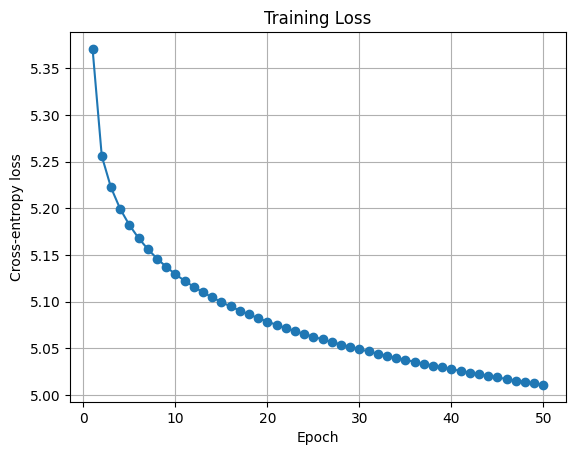

In [ ]:
import matplotlib.pyplot as plt

plt.plot(
    range(1, epochs + 1),
    loss_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training Loss")
plt.grid()
plt.show()

In [ ]:
# Frequency-based baseline
target_counts = np.bincount(Y, minlength=vocab_size)
probs = target_counts[target_counts > 0] / len(Y)

frequency_loss = -np.sum(probs * np.log(probs))

# Empirical conditional entropy
input_counts = np.bincount(X, minlength=vocab_size)

pairs = X * vocab_size + Y

unique_pairs, pair_counts = np.unique(
    pairs, return_counts=True
)

input_words = unique_pairs // vocab_size

conditional_probs = pair_counts / input_counts[input_words]

minimum_loss = -np.sum(
    (pair_counts / len(X)) * np.log(conditional_probs)
)

print("Uniform baseline:", np.log(vocab_size))
print("Frequency baseline:", frequency_loss)
print("Theoretical minimum training loss:", minimum_loss)
print("Current model loss:", loss_history[-1])
print("Remaining loss gap:", loss_history[-1] - minimum_loss)

Uniform baseline: 6.802394763324311
Frequency baseline: 5.3924478422855655
Theoretical minimum training loss: 4.704310831250864
Current model loss: 5.010591
Remaining loss gap: 0.3062801988699855


In [ ]:
epochs = 50
batch_size = 128
learning_rate = 0.003
epsilon = 1e-8

beta1 = 0.9
beta2 = 0.999

# First moments
m_E = np.zeros_like(embedding_matrix)
m_W = np.zeros_like(W)
m_b = np.zeros_like(b)

# Second moments
v_E = np.zeros_like(embedding_matrix)
v_W = np.zeros_like(W)
v_b = np.zeros_like(b)

t = 0

rng = np.random.default_rng(42)
adam_loss_history = []

In [ ]:
def adam_update(param, grad, m, v, t):

    # Update first moment
    m *= beta1
    m += (1 - beta1) * grad

    # Update second moment
    v *= beta2
    v += (1 - beta2) * grad**2

    # Bias correction
    m_hat = m / (1 - beta1**t)
    v_hat = v / (1 - beta2**t)

    # Update parameter
    param -= learning_rate * m_hat / (
        np.sqrt(v_hat) + epsilon
    )

In [ ]:
for epoch in range(epochs):

    permutation = rng.permutation(len(X))
    total_loss = 0.0

    for start in range(0, len(X), batch_size):

        batch = permutation[start:start + batch_size]

        inputs = X[batch]
        targets = Y[batch]

        n = len(batch)
        rows = np.arange(n)

        # -------------------------
        # FORWARD PROPAGATION
        # -------------------------

        x = embedding_matrix[inputs]

        z = x @ W + b

        # Numerically stable softmax
        z -= np.max(z, axis=1, keepdims=True)

        target_scores = z[rows, targets]

        np.exp(z, out=z)

        normalizers = np.sum(z, axis=1, keepdims=True)

        predictions = z / normalizers

        # Cross-entropy loss
        loss = np.log(normalizers[:, 0]) - target_scores

        total_loss += np.sum(loss)

        # -------------------------
        # BACKPROPAGATION
        # -------------------------

        dz = predictions
        dz[rows, targets] -= 1
        dz /= n

        dW = x.T @ dz
        db = np.sum(dz, axis=0)
        dx = dz @ W.T

        # Embedding matrix gradients
        dE = np.zeros_like(embedding_matrix)

        np.add.at(dE, inputs, dx)

        # -------------------------
        # ADAM OPTIMIZATION
        # -------------------------

        t += 1

        adam_update(W, dW, m_W, v_W, t)
        adam_update(b, db, m_b, v_b, t)

        adam_update(
            embedding_matrix, dE, m_E, v_E, t
        )

    average_loss = total_loss / len(X)

    adam_loss_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {average_loss:.6f}"
    )

Epoch 1/50 | Loss: 5.101716
Epoch 2/50 | Loss: 5.062841
Epoch 3/50 | Loss: 5.033813
Epoch 4/50 | Loss: 5.011591
Epoch 5/50 | Loss: 4.995656
Epoch 6/50 | Loss: 4.983286
Epoch 7/50 | Loss: 4.974243
Epoch 8/50 | Loss: 4.967033
Epoch 9/50 | Loss: 4.961469
Epoch 10/50 | Loss: 4.956789
Epoch 11/50 | Loss: 4.952410
Epoch 12/50 | Loss: 4.949469
Epoch 13/50 | Loss: 4.946640
Epoch 14/50 | Loss: 4.943920
Epoch 15/50 | Loss: 4.941771
Epoch 16/50 | Loss: 4.940331
Epoch 17/50 | Loss: 4.938724
Epoch 18/50 | Loss: 4.937144
Epoch 19/50 | Loss: 4.936395
Epoch 20/50 | Loss: 4.934854
Epoch 21/50 | Loss: 4.934008
Epoch 22/50 | Loss: 4.932950
Epoch 23/50 | Loss: 4.932550
Epoch 24/50 | Loss: 4.931657
Epoch 25/50 | Loss: 4.930584
Epoch 26/50 | Loss: 4.930060
Epoch 27/50 | Loss: 4.929314
Epoch 28/50 | Loss: 4.928780
Epoch 29/50 | Loss: 4.928622
Epoch 30/50 | Loss: 4.927690
Epoch 31/50 | Loss: 4.926991
Epoch 32/50 | Loss: 4.926739
Epoch 33/50 | Loss: 4.926334
Epoch 34/50 | Loss: 4.926739
Epoch 35/50 | Loss: 4.9

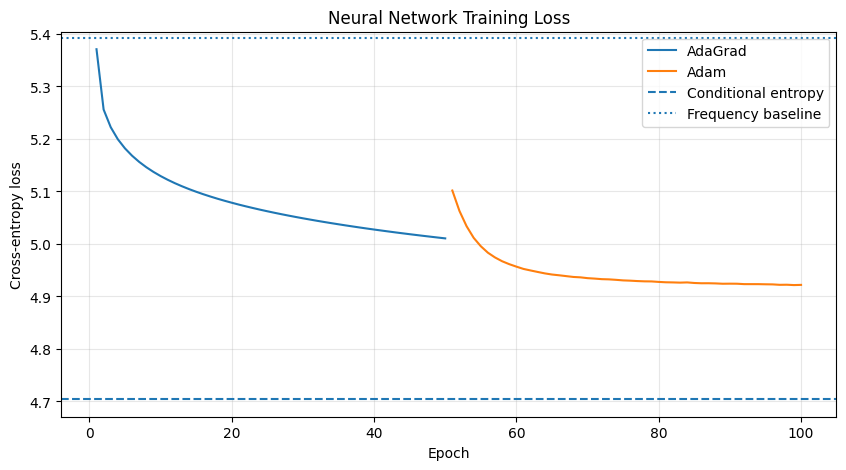

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    label="AdaGrad"
)

plt.plot(
    range(len(loss_history) + 1,
          len(loss_history) + len(adam_loss_history) + 1),
    adam_loss_history,
    label="Adam"
)

plt.axhline(
    y=4.704310831250864,
    linestyle="--",
    label="Conditional entropy"
)

plt.axhline(
    y=5.3924478422855655,
    linestyle=":",
    label="Frequency baseline"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Neural Network Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()

test = pd.read_csv("test.csv", dtype=str, keep_default_na=False)

print(test.head())
print(test.columns)
print("Number of test pairs:", len(test))

Saving test.csv to test.csv
     pair_id    token1    token2
0  pair_0001  tok_0491  tok_0759
1  pair_0002  tok_0132  tok_0182
2  pair_0003  tok_0062  tok_0474
3  pair_0004  tok_0141  tok_0243
4  pair_0005  tok_0594  tok_0843
Index(['pair_id', 'token1', 'token2'], dtype='object')
Number of test pairs: 1200


In [ ]:
def cosine_similarity(word1, word2):

    # Handle words missing from the vocabulary
    if word1 not in word_to_idx or word2 not in word_to_idx:
        return 0.5

    # Retrieve trained embedding vectors
    e1 = embedding_matrix[word_to_idx[word1]]
    e2 = embedding_matrix[word_to_idx[word2]]

    # Calculate vector magnitudes
    denominator = np.linalg.norm(e1) * np.linalg.norm(e2)

    if denominator == 0:
        return 0.5

    # Calculate cosine similarity
    similarity = np.dot(e1, e2) / denominator

    # Rescale from [-1, 1] to [0, 1]
    similarity = (similarity + 1) / 2

    return float(np.clip(similarity, 0, 1))

In [ ]:
word_columns = [
    col for col in test.columns if col != "pair_id"
]

assert len(word_columns) == 2, "Check test dataset columns."

word1_col, word2_col = word_columns

similarities = [
    cosine_similarity(word1, word2)
    for word1, word2 in zip(
        test[word1_col], test[word2_col]
    )
]

submission = pd.DataFrame({
    "pair_id": test["pair_id"],
    "similarity": similarities
})

print(submission.head(10))

     pair_id  similarity
0  pair_0001    0.599662
1  pair_0002    0.554479
2  pair_0003    0.680481
3  pair_0004    0.585993
4  pair_0005    0.559747
5  pair_0006    0.560992
6  pair_0007    0.621941
7  pair_0008    0.539359
8  pair_0009    0.493277
9  pair_0010    0.522760


In [ ]:
# Validate submission
assert len(submission) == 1200
assert submission["pair_id"].is_unique
assert submission["similarity"].between(0, 1).all()
assert submission.isna().sum().sum() == 0

# Save submission
submission.to_csv("submission.csv", index=False)

# Download submission
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>